# Strategy Grid

This notebook builds the backtesting framework and runs a large grid of strategy variants on the in-sample data. Each strategy is defined by the positions it holds each day, and every variant is run through the same backtest so that results can be compared fairly against a buy-and-hold benchmark.

Positions are decided at each day's close and held from the next day on, so no strategy uses information that would not have been available at the time. The out-of-sample data is not used in this notebook.

In [1]:
# Importing the necessary packages and functions
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from functions import *

## Data

In-sample price data (2006–2020) is downloaded for the asset being tested, and daily close-to-close returns are calculated for use in every backtest.

In [2]:
# Getting the required data
ticker, start_date, end_date = 'SPY', '2006-01-01', '2021-01-01'
SPY_data = get_data(ticker, start_date, end_date)

# Function to calculate the close-to-close returns for a ticker
def daily_returns(ticker_data):
    current = ticker_data['Close']
    previous = current.shift(1)                  # yesterday's close lined up with today's
    returns = (current - previous) / previous    # % change from yesterday to today
    returns = returns.fillna(0)                  # first day has no previous close
    return returns

[*********************100%***********************]  1 of 1 completed


## Backtest Functions

Each strategy outputs the position it holds each day. These functions turn positions into daily returns and cumulative growth. Positions are shifted forward one day so trades are based only on information available at the previous close.

In [3]:
# Function to calculate a strategy's daily returns
def strategy_returns(positions, asset_returns, cost=0.0):
    position = positions.shift(1).fillna(0)              # today you hold what you decided at yesterday's close
    previous_position = position.shift(1).fillna(0)      # what you held the day before
    trade_size = (position - previous_position).abs()    # how much you bought or sold to get to today's position
    gross_returns = position * asset_returns             # return earned on the position held
    trading_costs = cost * trade_size                    # cost paid on the amount traded
    net_returns = gross_returns - trading_costs   
    return net_returns

# Function to calculate cumulative % growth
def cumulative_return(returns):
    daily_growth = 1 + returns                         # e.g. a +2% day becomes 1.02
    cumulative_growth = daily_growth.cumprod()         # value of $1 invested at the start
    percent_return = 100 * (cumulative_growth - 1)     # convert to % gain
    return percent_return

## Performance Metrics

Each strategy is evaluated on annualized return, annualized volatility, Sharpe ratio, and maximum drawdown. All annualized figures assume 252 trading days per year, and the Sharpe ratio assumes a risk-free rate of zero.

In [4]:
# Function to calculate annualized return
def annualized_return(returns):
    total_growth = (1 + returns).prod()                # final value of $1
    years = (len(returns) - 1) / 252                   # 252 trading days in a year
    ann_return = total_growth ** (1 / years) - 1
    return ann_return

# Function to calculate annualized volatility
def annualized_volatility(returns):
    daily_volatility = returns.std()
    ann_vol = daily_volatility * np.sqrt(252)
    return ann_vol

# Function to calculate the Sharpe ratio
def sharpe_ratio(returns):
    annual_mean = returns.mean() * 252
    annual_volatility = annualized_volatility(returns)
    if annual_volatility == 0:                            # if no movement in the strategy
        return 0.0
    sharpe = annual_mean / annual_volatility
    return sharpe

# Function to calculate maximum drawdown
def max_drawdown(returns):
    cumulative_growth = (1 + returns).cumprod()
    running_peak = cumulative_growth.cummax()             # highest value reached up to each day
    drawdown = cumulative_growth / running_peak - 1       # % below that peak
    worst_drawdown = drawdown.min()                       # most negative = worst drawdown
    return worst_drawdown

# Function to calculate all performance metrics at once
def performance_metrics(returns):
    ann_return = annualized_return(returns)
    ann_vol = annualized_volatility(returns)
    sharpe = sharpe_ratio(returns)
    worst_drawdown = max_drawdown(returns)
    return ann_return, ann_vol, sharpe, worst_drawdown

# Function to summarize all metrics for one strategy
def summary(returns):
    ann_return, ann_vol, sharpe, worst_drawdown = performance_metrics(returns)
    return {'Ann. Return': ann_return, 
            'Ann. Volatility': ann_vol, 
            'Sharpe': sharpe, 
            'Max Drawdown': worst_drawdown}

## Buy-and-Hold Benchmark

Buy-and-hold holds a position of 1 every day and is the benchmark every strategy variant is compared against. Its cumulative return is also checked against the return calculated directly from prices to confirm the backtest functions work correctly.

In [5]:
# Running the buy-and-hold strategy
SPY_returns = daily_returns(SPY_data)
SPY_bh_positions = pd.Series(1.0, index=SPY_data.index)
SPY_bh_returns = strategy_returns(SPY_bh_positions, SPY_returns)

# Checking the backtest against the return calculated directly from prices
from_backtest = cumulative_return(SPY_bh_returns).iloc[-1]
from_prices = 100 * (SPY_data['Close'].iloc[-1] / SPY_data['Close'].iloc[0] - 1)
print(f'From backtest: {from_backtest:.4f}%')
print(f'From prices:   {from_prices:.4f}%')

# Buy-and-hold performance summary
pd.Series(summary(SPY_bh_returns)).round(4)

From backtest: 299.0339%
From prices:   299.0339%


Ann. Return        0.0968
Ann. Volatility    0.2008
Sharpe             0.5605
Max Drawdown      -0.5519
dtype: float64

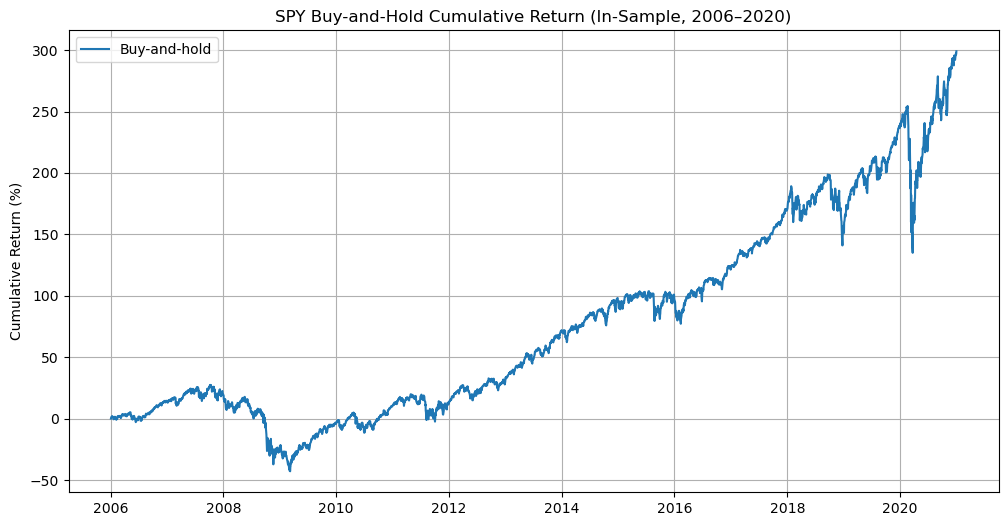

In [6]:
# Plotting buy-and-hold cumulative return
plt.figure(figsize=(12, 6))
plt.plot(cumulative_return(SPY_bh_returns), label='Buy-and-hold')
plt.title(f'{ticker} Buy-and-Hold Cumulative Return (In-Sample, 2006–2020)')
plt.ylabel('Cumulative Return (%)')
plt.legend()
plt.grid(True)
plt.show()

## Strategy Grid

The grid currently contains two families of random strategies, which have no skill by construction, as each day's position is drawn independently of past prices from a symmetric distribution with an expected value of 0. They act as a control group, so any random strategy that performs well in-sample is a false discovery. Every strategy is run through the same backtest and evaluated on the same 2006–2020 in-sample period as the buy-and-hold benchmark.

In [7]:
# Setting the grid size and a fixed random seed so the random strategies are the same every run
n_strategies, seed = 5000, 8162004

### Random Long/Short Strategies

Each strategy holds a position of −1 or +1 each day with equal probability.

In [8]:
# Function to generate random positions of -1 or +1 with equal probability
def random_long_short_positions(index, rng):
    positions = rng.choice([-1.0, 1.0], size=len(index))
    long_short_positions = pd.Series(positions, index=index)
    return long_short_positions

### Random Continuous Strategies

Each strategy draws its daily position from [−1, 1] with density f(x) = 3x²/2, which keeps most positions close to fully long or fully short. Positions are sampled using the inverse of the cumulative distribution function.

In [9]:
# Function to generate random positions in [-1, 1] with density f(x) = 3x^2/2
def random_continuous_positions(index, rng):
    y = rng.uniform(0, 1, size=len(index))
    positions = np.cbrt(2*y - 1)              # inverse CDF of f(x) = 3x^2/2 (derived in report)
    continuous_positions = pd.Series(positions, index=index)
    return continuous_positions

### Running the Grid

Each family is run 5,000 times through the same backtest. Every 40th strategy's daily returns are also kept so that a sample of 250 strategies can be plotted.

In [10]:
# Function to run every random strategy through the backtest (and keep a sample for visualization)
def run_random_grid(ticker, ticker_data, asset_returns, n_strategies, seed, sample_every=40):
    rng = np.random.default_rng(seed)            # same seed gives the same strategies every run
    results = {}
    sample_returns = {}
    for k in range(n_strategies):
        positions = random_long_short_positions(ticker_data.index, rng)
        returns = strategy_returns(positions, asset_returns)
        results[f'{ticker}_Long_Short_{k}'] = summary(returns)
        if k % sample_every == 0:
            sample_returns[f'{ticker}_Long_Short_{k}'] = returns
    for k in range(n_strategies):
        positions = random_continuous_positions(ticker_data.index, rng)
        returns = strategy_returns(positions, asset_returns)
        results[f'{ticker}_Continuous_{k}'] = summary(returns)
        if k % sample_every == 0:
            sample_returns[f'{ticker}_Continuous_{k}'] = returns
    results_df = pd.DataFrame(results).T
    return results_df, sample_returns

# Running every random strategy through the backtest (and keeping every 40th, 250 in total, for visualization)
results_df, sample_returns = run_random_grid(ticker, SPY_data, SPY_returns, n_strategies, seed)

## In-Sample Results

The strategies are ranked by Sharpe ratio and compared against the buy-and-hold benchmark. Since none of these strategies have any skill, any that beat buy-and-hold do so by luck alone.

### Simulated Paths

A sample of random strategies is plotted against buy-and-hold. Most finish below zero, but a few outperform buy-and-hold.

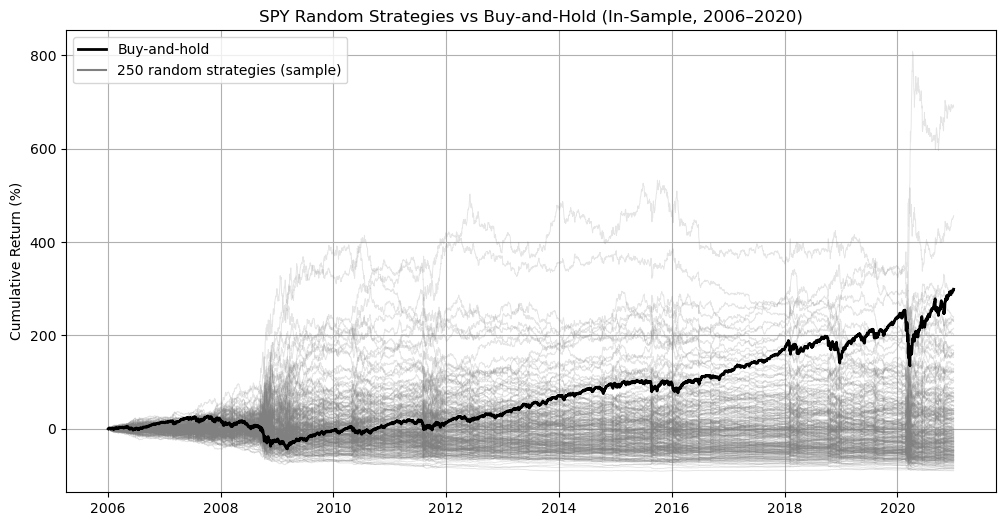

In [11]:
# Plotting the sample of 250 random strategies against buy-and-hold
plt.figure(figsize=(12, 6))
for name, returns in sample_returns.items():
    plt.plot(cumulative_return(returns), color='grey', alpha=0.2, linewidth=0.7)
plt.plot(cumulative_return(SPY_bh_returns), color='black', linewidth=2, label='Buy-and-hold')
plt.plot([], [], color='grey', label=f'{len(sample_returns)} random strategies (sample)')
plt.title(f'{ticker} Random Strategies vs Buy-and-Hold (In-Sample, 2006–2020)')
plt.ylabel('Cumulative Return (%)')
plt.legend()
plt.grid(True)
plt.show()

### Best Performing Strategies

The ten random strategies with the highest in-sample Sharpe ratios. Several beat buy-and-hold on both return and drawdown despite having no skill.

In [12]:
# Top 10 strategies by Sharpe ratio
results_df.sort_values('Sharpe', ascending=False).head(10).round(4)

,Ann. Return,Ann. Volatility,Sharpe,Max Drawdown
SPY_Continuous_3296,0.1469,0.1553,0.9593,-0.2232
SPY_Long_Short_2994,0.1730,0.2006,0.8947,-0.3559
SPY_Continuous_1230,0.1260,0.1508,0.8620,-0.2428
SPY_Continuous_455,0.1273,0.1572,0.8397,-0.2279
SPY_Long_Short_377,0.1553,0.2007,0.8196,-0.3420
SPY_Long_Short_2576,0.1544,0.2007,0.8151,-0.3444
SPY_Long_Short_1211,0.1499,0.2007,0.7955,-0.3263
SPY_Long_Short_2880,0.1479,0.2007,0.7871,-0.2747
SPY_Long_Short_2619,0.1470,0.2007,0.7826,-0.3029
SPY_Continuous_2574,0.1146,0.1547,0.7786,-0.3431


### Strategies that Beat Buy-and-Hold

The number of random strategies whose Sharpe ratio is higher than buy-and-hold's.

In [13]:
# How many random strategies beat buy-and-hold
SPY_bh_sharpe = sharpe_ratio(SPY_bh_returns)
n_beat = (results_df['Sharpe'] > SPY_bh_sharpe).sum()
print(f'Buy-and-hold Sharpe: {SPY_bh_sharpe:.4f}')
print(f'Random strategies that beat buy-and-hold: {n_beat} of {len(results_df)}')

Buy-and-hold Sharpe: 0.5605
Random strategies that beat buy-and-hold: 161 of 10000


### Distribution of Sharpe Ratios

The Sharpe ratios of both families are centred around zero, as expected for strategies with no skill. The strategies to the right of the dashed line beat buy-and-hold.

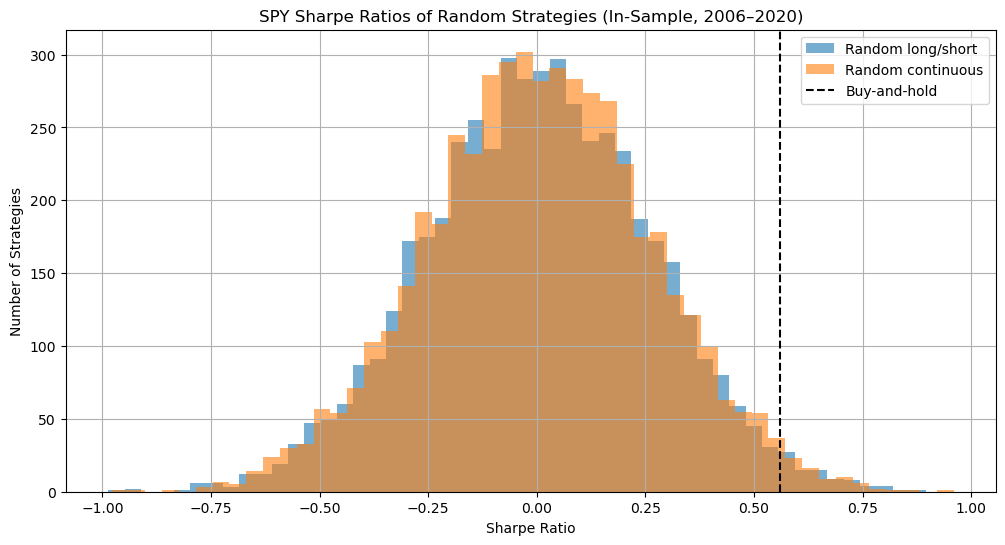

In [15]:
# Distribution of Sharpe ratios for each random family
plt.figure(figsize=(12, 6))
plt.hist(results_df.loc[results_df.index.str.startswith(f'{ticker}_Long_Short'), 'Sharpe'], bins=50, alpha=0.6, label='Random long/short')
plt.hist(results_df.loc[results_df.index.str.startswith(f'{ticker}_Continuous'), 'Sharpe'], bins=50, alpha=0.6, label='Random continuous')
plt.axvline(SPY_bh_sharpe, linestyle='--', color='black', label='Buy-and-hold')
plt.title(f'{ticker} Sharpe Ratios of Random Strategies (In-Sample, 2006–2020)')
plt.xlabel('Sharpe Ratio')
plt.ylabel('Number of Strategies')
plt.legend()
plt.grid(True)
plt.show()

## Summary

Of 10,000 random strategies with no skill, 161 (1.6%) beat buy-and-hold's in-sample Sharpe ratio of 0.56, and the best reached a Sharpe ratio of 0.96 with a smaller maximum drawdown than buy-and-hold. These results come from luck alone, and are tested for statistical significance in the next notebook.